# 07 — CTU-13 Cross-Scenario Drift & Botnet Threshold Audit

**Thay thế Notebook 07 “Topology & Beaconing” đối với CTU-13 Parquet hiện tại.** File này không có source IP, destination IP, timestamp; không suy diễn graph/topology, beaconing hay thứ tự thời gian từ dòng dữ liệu.

**Câu hỏi nghiên cứu:** Vì sao Random Forest phát hiện Botnet kém khi chuyển giữa scenario 5 (train), scenario 11 (validation) và scenario 12 (test)? Liệu hiệu chỉnh ngưỡng **chỉ trên validation** có giúp tăng Botnet F1/Recall mà kiểm soát FPR không?

**Giao thức:** Nhãn được xác định BOTNET/NORMAL; BACKGROUND/UNKNOWN không tham gia supervised metrics. Dữ liệu preprocessing chỉ fit trên train. Model cố định từ Notebook 06 nếu cung cấp output; fallback tái huấn luyện cùng RF của Notebook 06 từ train. **Chọn threshold duy nhất từ validation**; không xem kết quả test trước khi chốt. Test scenario 12 đã được kiểm tra ở các notebook trước nên kết quả ở đây là exploratory, không phải blind independent evaluation.

**Đầu ra:** schema/label audit, feature drift, categorical drift, validation PR/ROC + threshold grid, selected threshold, classification report 2 lớp, confusion matrices, predictions, manifest.


## 0. Cấu hình và dependencies

In [86]:
from pathlib import Path
import os, re, io, json, zipfile, warnings, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
    precision_recall_curve, roc_curve, roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score)
from scipy.spatial.distance import jensenshannon

SEED=42
SPLITS={'train':5, 'validation':11, 'test':12}
NUMERIC=['dur','stos','dtos','tot_pkts','tot_bytes','src_bytes']
CATEGORICAL=['proto','dir','state']
FEATURES=NUMERIC+CATEGORICAL
CTU_PATH=os.getenv('CTU_PATH','').strip() # optional manual CTU folder / ZIP
MODEL_06_PATH=os.getenv('MODEL_06_PATH','').strip() # optional Notebook 06 ctu_flow_only_rf.joblib
MAX_TRAIN_ROWS=None # remain None for Notebook 06 parity
FPR_LIMIT=0.10 # choose max validation Botnet F1 among thresholds with FPR <= 10%, if feasible
MIN_VALIDATION_RECALL=0.0 # optional desired recall; constraint applied only if feasible
THRESHOLD_GRID=np.linspace(0.01,0.99,99)
OUT=Path('/kaggle/working/nids_outputs/07_CTU_CrossScenario_Drift' if Path('/kaggle/working').exists() else './nids_outputs/07_CTU_CrossScenario_Drift')
OUT.mkdir(parents=True,exist_ok=True)
print('Output:',OUT.resolve())

Output: /kaggle/working/nids_outputs/07_CTU_CrossScenario_Drift


## 1. Tìm CTU-13 và kiểm tra schema (hard gate)

In [87]:
PREFERRED=Path('/kaggle/input/datasets/chienvoo/nids-se-at-cnn-data/ctu-13-dataset')
def discover_source():
    if CTU_PATH:
        p=Path(CTU_PATH)
        if p.is_dir():return 'directory',p
        if p.is_file() and p.suffix.lower()=='.zip':return 'zip',p
        raise FileNotFoundError(f'CTU_PATH missing/not directory/ZIP: {p}')
    if PREFERRED.is_dir() and list(PREFERRED.glob('*.binetflow.parquet')):
        return 'directory',PREFERRED
    root=Path('/kaggle/input') if Path('/kaggle/input').is_dir() else Path('/mnt/data')
    dirs=sorted({p.parent for p in root.rglob('*.binetflow.parquet')})
    if len(dirs)==1:return 'directory',dirs[0]
    if len(dirs)>1:raise RuntimeError(f'Multiple CTU sources: {dirs}. Set CTU_PATH.')
    zips=[]
    for zpath in root.rglob('*.zip'):
        try:
            with zipfile.ZipFile(zpath) as z:
                hits=[x for x in z.namelist() if re.search(r'(^|/)\d+-[^/]+\.binetflow\.parquet$',x)]
                if len(hits)>=3:zips.append(zpath)
        except (OSError, zipfile.BadZipFile):continue
    if len(zips)==1:return 'zip',zips[0]
    raise FileNotFoundError(f'Could not uniquely locate CTU Parquet: directories={dirs}, zips={zips}. Specify CTU_PATH.')
source_type,source_path=discover_source()
if source_type=='directory':items=[(q.name,q) for q in source_path.rglob('*.binetflow.parquet')]
else:
    with zipfile.ZipFile(source_path) as z:
        items=[(Path(name).name,name) for name in z.namelist() if name.endswith('.binetflow.parquet')]
files={}
for name,location in items:
    m=re.match(r'^(\d+)-',name)
    if not m:continue
    sid=int(m.group(1))
    if sid in files:raise ValueError(f'Duplicate scenario ID {sid}')
    files[sid]=location
assert set(SPLITS.values()).issubset(files),f'Scenarios missing: {set(SPLITS.values())-set(files)}'
def read_scenario(sid):
    if source_type=='directory':df=pd.read_parquet(files[sid])
    else:
        with zipfile.ZipFile(source_path) as z:df=pd.read_parquet(io.BytesIO(z.read(files[sid])))
    df.columns=df.columns.astype(str).str.strip()
    return df
frames={name:read_scenario(sid) for name,sid in SPLITS.items()}
cols={split:set(df.columns) for split,df in frames.items()}
assert all(v==cols['train'] for v in cols.values()),'Scenario schemas differ; investigate.'
assert set(FEATURES+['label']).issubset(cols['train']),f'Missing features: {set(FEATURES+['label'])-cols["train"]}'
normalized={re.sub('[^a-z0-9]','',c.lower()):c for c in cols['train']}
source_ip=next((normalized[k] for k in ('srcaddr','srcip','sourceip') if k in normalized),None)
dest_ip=next((normalized[k] for k in ('dstaddr','dstip','destinationip') if k in normalized),None)
tstamp=next((normalized[k] for k in ('starttime','timestamp','flowstarttime','time') if k in normalized),None)
readiness={'source_ip':source_ip,'dest_ip':dest_ip,'timestamp':tstamp,
           'graph_feasible':bool(source_ip and dest_ip),
           'beacon_feasible':bool(source_ip and dest_ip and tstamp)}
(OUT/'schema_readiness.json').write_text(json.dumps(readiness,indent=2))
print('CTU source:',source_path)
print('Columns:',sorted(cols['train']))
print('Rows:',{s:len(df) for s,df in frames.items()})
print('Graph/time feasibility:',readiness)
if not readiness['graph_feasible']:print('NO HOST GRAPH OR BEACONING: missing endpoints; this notebook performs flow drift diagnostics only.')

CTU source: /kaggle/input/datasets/chienvoo/nids-se-at-cnn-data/ctu-13-dataset
Columns: ['Family', 'dir', 'dtos', 'dur', 'label', 'proto', 'src_bytes', 'state', 'stos', 'tot_bytes', 'tot_pkts']
Rows: {'train': 92900, 'validation': 72359, 'test': 218917}
Graph/time feasibility: {'source_ip': None, 'dest_ip': None, 'timestamp': None, 'graph_feasible': False, 'beacon_feasible': False}
NO HOST GRAPH OR BEACONING: missing endpoints; this notebook performs flow drift diagnostics only.


## 2. Label audit và dữ liệu có nhãn xác định

In [88]:
def label_group(raw):
    if pd.isna(raw):return 'UNKNOWN'
    s=str(raw).strip().lower()
    if s.startswith('flow='):s=s[5:]
    if s.startswith('from-botnet'):return 'BOTNET'
    if s.startswith('from-normal') or s.startswith('normal-'):return 'NORMAL'
    return 'UNKNOWN'
rows=[];X={};Y={}
for split,df in frames.items():
    group=df['label'].map(label_group)
    counts=group.value_counts()
    rows.append({'split':split,'scenario':SPLITS[split], 'total':len(df),
        'normal':int(counts.get('NORMAL',0)),'botnet':int(counts.get('BOTNET',0)),
        'unknown':int(counts.get('UNKNOWN',0)),
        'botnet_prior_known':float(counts.get('BOTNET',0)/max(1,counts.get('NORMAL',0)+counts.get('BOTNET',0)))})
    sel=group.isin(['NORMAL','BOTNET'])
    data=df.loc[sel,FEATURES].copy()
    for c in NUMERIC:data[c]=pd.to_numeric(data[c],errors='coerce').replace([np.inf,-np.inf],np.nan)
    for c in CATEGORICAL:data[c]=data[c].astype('object').where(data[c].notna(),np.nan)
    X[split]=data; Y[split]=(group.loc[sel]=='BOTNET').astype(int).to_numpy()
lab=pd.DataFrame(rows)
display(lab);lab.to_csv(OUT/'scenario_label_audit.csv',index=False)
assert len(np.unique(Y['train']))==2 and len(np.unique(Y['validation']))==2 and len(np.unique(Y['test']))==2
print('UNKNOWN excluded from supervised metrics, not treated as NORMAL.')

,split,scenario,total,normal,botnet,unknown,botnet_prior_known
0,train,5,92900,4467,880,87553,0.164578
1,validation,11,72359,1507,786,70066,0.342782
2,test,12,218917,6885,2000,210032,0.225098


UNKNOWN excluded from supervised metrics, not treated as NORMAL.


## 3. Distribution shift: numeric PSI/KS và categorical Jensen–Shannon

In [89]:
from scipy.stats import ks_2samp

def psi_reference_bins(base,other,n_bins=10):
    base=np.asarray(base,dtype=float);other=np.asarray(other,dtype=float)
    base=base[np.isfinite(base)];other=other[np.isfinite(other)]
    if len(base)<5 or len(other)<5:return np.nan
    edges=np.unique(np.quantile(base,np.linspace(0,1,n_bins+1)))
    if len(edges)<3:return 0.0 if np.nanmedian(base)==np.nanmedian(other) else np.nan
    edges[0]=-np.inf;edges[-1]=np.inf
    p=np.histogram(base,bins=edges)[0].astype(float);q=np.histogram(other,bins=edges)[0].astype(float)
    p=np.clip(p/p.sum(),1e-6,None);q=np.clip(q/q.sum(),1e-6,None)
    return float(np.sum((p-q)*np.log(p/q)))
records=[]
for col in NUMERIC:
    ref=X['train'][col].to_numpy(dtype=float)
    for split in ('validation','test'):
        alt=X[split][col].to_numpy(dtype=float)
        ra=ref[np.isfinite(ref)];rb=alt[np.isfinite(alt)]
        records.append({'feature':col,'type':'numeric','comparison':f'train_vs_{split}',
            'psi':psi_reference_bins(ra,rb),'ks_stat':float(ks_2samp(ra,rb).statistic) if len(ra) and len(rb) else np.nan,
            'js_divergence':np.nan,'train_median':float(np.median(ra)) if len(ra) else np.nan,
            'other_median':float(np.median(rb)) if len(rb) else np.nan})
for col in CATEGORICAL:
    a=X['train'][col].fillna('__MISSING__').astype(str).value_counts(normalize=True)
    for split in ('validation','test'):
        b=X[split][col].fillna('__MISSING__').astype(str).value_counts(normalize=True)
        keys=a.index.union(b.index)
        js=float(jensenshannon(a.reindex(keys,fill_value=0),b.reindex(keys,fill_value=0),base=2)**2)
        records.append({'feature':col,'type':'categorical','comparison':f'train_vs_{split}',
            'psi':np.nan,'ks_stat':np.nan,'js_divergence':js,'train_median':np.nan,'other_median':np.nan})
drift=pd.DataFrame(records)
display(drift.sort_values(['comparison','psi','js_divergence'],ascending=[True,False,False]).reset_index(drop=True))
drift.to_csv(OUT/'feature_distribution_drift.csv',index=False)
print('PSI and JS are descriptive shift indicators, not proofs of causal model failure.')

,feature,type,comparison,psi,ks_stat,js_divergence,train_median,other_median
0,dur,numeric,train_vs_test,0.190466,0.113975,NaN,0.021872,0.035822
1,tot_bytes,numeric,train_vs_test,0.124241,0.079498,NaN,366.000000,412.000000
2,src_bytes,numeric,train_vs_test,0.054069,0.111104,NaN,88.000000,148.000000
3,tot_pkts,numeric,train_vs_test,0.011127,0.033475,NaN,2.000000,2.000000
4,stos,numeric,train_vs_test,0.000000,0.000000,NaN,0.000000,0.000000
5,dtos,numeric,train_vs_test,0.000000,0.000121,NaN,0.000000,0.000000
6,state,categorical,train_vs_test,NaN,NaN,0.086695,NaN,NaN
7,proto,categorical,train_vs_test,NaN,NaN,0.007192,NaN,NaN
8,dir,categorical,train_vs_test,NaN,NaN,0.000772,NaN,NaN
9,tot_pkts,numeric,train_vs_validation,2.505828,0.342907,NaN,2.000000,2.000000


PSI and JS are descriptive shift indicators, not proofs of causal model failure.


## 4. Khôi phục baseline Notebook 06 (hoặc tái huấn luyện đúng cấu hình)

In [90]:
def discover_model_06():
    if MODEL_06_PATH:
        p=Path(MODEL_06_PATH)
        if not p.is_file():raise FileNotFoundError(p)
        return p
    root=Path('/kaggle/input') if Path('/kaggle/input').is_dir() else Path('/mnt/data')
    candidates=sorted(root.rglob('ctu_flow_only_rf.joblib'))
    if len(candidates)==1:return candidates[0]
    if len(candidates)>1:raise RuntimeError(f'Multiple 06 model files. Set MODEL_06_PATH: {candidates}')
    return None
modelpath=discover_model_06()
if modelpath:
    model=joblib.load(modelpath)
    assert hasattr(model,'predict_proba')
    print('Loaded frozen 06 model:',modelpath)
    model_origin='notebook06_checkpoint'
else:
    print('Notebook 06 checkpoint missing; training same RF config on scenario 5 ONLY.')
    preprocess=ColumnTransformer([
      ('num',Pipeline([('imputer',SimpleImputer(strategy='median'))]),NUMERIC),
      ('cat',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),
                       ('onehot',OneHotEncoder(handle_unknown='ignore'))]),CATEGORICAL)],remainder='drop')
    rf=RandomForestClassifier(n_estimators=120,max_depth=18,min_samples_leaf=3,
                              class_weight='balanced_subsample',n_jobs=-1,random_state=SEED)
    model=Pipeline([('preprocess',preprocess),('classifier',rf)])
    model.fit(X['train'],Y['train']);model_origin='retrained_06_configuration'
joblib.dump(model,OUT/'ctu_rf_frozen.joblib')
probs={split:model.predict_proba(X[split])[:,1] for split in ('validation','test')}
assert all(len(probs[s])==len(Y[s]) and np.isfinite(probs[s]).all() for s in probs)
print('Model origin:',model_origin)

Notebook 06 checkpoint missing; training same RF config on scenario 5 ONLY.
Model origin: retrained_06_configuration


## 5. Validation threshold sweep — không dùng test để chọn

Selected threshold: 0.5800000000000001 constraint: FPR <= 0.1


,setting,threshold,accuracy,botnet_precision,botnet_recall,botnet_f1,macro_f1,fpr,TN,FP,FN,TP
0,default_0.50,0.50,0.338421,0.004071,0.003817,0.003940,0.254337,0.487060,773.0,734.0,783.0,3.0
1,validation_selected,0.58,0.657218,0.500000,0.003817,0.007576,0.400203,0.001991,1504.0,3.0,783.0,3.0


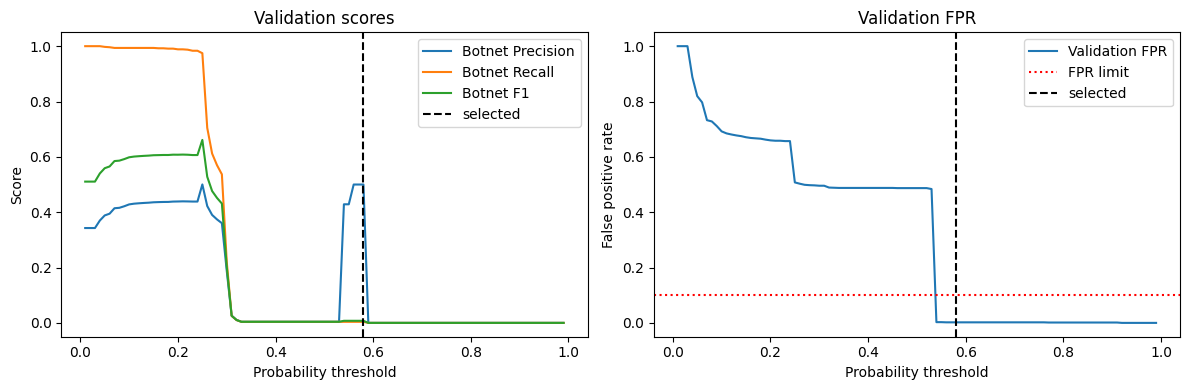

In [91]:
def calc_metrics(y,pred):
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {'accuracy':float(accuracy_score(y,pred)),
      'botnet_precision':float(precision_score(y,pred,zero_division=0)),
      'botnet_recall':float(recall_score(y,pred,zero_division=0)),
      'botnet_f1':float(f1_score(y,pred,zero_division=0)),
      'macro_f1':float(f1_score(y,pred,average='macro',zero_division=0)),
      'fpr':float(fp/(fp+tn)) if fp+tn else None,
      'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)}
yv=Y['validation'];pv=probs['validation']
rows=[]
for t in THRESHOLD_GRID:
    row={'threshold':float(t),**calc_metrics(yv,(pv>=t).astype(int))}
    rows.append(row)
grid=pd.DataFrame(rows)
grid.to_csv(OUT/'validation_threshold_grid.csv',index=False)
base=grid.iloc[(grid['threshold']-0.5).abs().argmin()]
feasible=grid[grid.fpr<=FPR_LIMIT].copy()
constraint='FPR <= '+str(FPR_LIMIT)
if MIN_VALIDATION_RECALL>0 and len(feasible):
    sub=feasible[feasible.botnet_recall>=MIN_VALIDATION_RECALL]
    if len(sub):feasible=sub;constraint+=f' and recall >= {MIN_VALIDATION_RECALL}'
if len(feasible)==0:
    warnings.warn('No threshold meets FPR bound on validation; falling back to highest validation Botnet F1 (UNCONSTRAINED).')
    feasible=grid;constraint='No feasible FPR bound: unconstrained Botnet F1'
# Deterministic tie-break: max F1, lower FPR, higher recall, higher threshold
winner=feasible.sort_values(['botnet_f1','fpr','botnet_recall','threshold'],ascending=[False,True,False,False]).iloc[0]
selected=float(winner.threshold)
selection={'threshold':selected,'criterion':'max validation BOTNET F1 with validation FPR constraint',
           'constraint':constraint,'fpr_limit':FPR_LIMIT,
           'validation_selected':winner.to_dict(),'validation_default_0_5':base.to_dict(),
           'test_not_used_for_selection':True}
(OUT/'validation_threshold_selection.json').write_text(json.dumps(selection,indent=2))
print('Selected threshold:',selected,'constraint:',constraint)
display(pd.DataFrame([{'setting':'default_0.50',**base.to_dict()},
                      {'setting':'validation_selected',**winner.to_dict()}]))
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].plot(grid.threshold,grid.botnet_precision,label='Botnet Precision')
axs[0].plot(grid.threshold,grid.botnet_recall,label='Botnet Recall')
axs[0].plot(grid.threshold,grid.botnet_f1,label='Botnet F1')
axs[0].axvline(selected,color='black',ls='--',label='selected')
axs[0].set(xlabel='Probability threshold',ylabel='Score',title='Validation scores');axs[0].legend()
axs[1].plot(grid.threshold,grid.fpr,label='Validation FPR')
axs[1].axhline(FPR_LIMIT,color='red',ls=':',label='FPR limit')
axs[1].axvline(selected,color='black',ls='--',label='selected')
axs[1].set(xlabel='Probability threshold',ylabel='False positive rate',title='Validation FPR');axs[1].legend()
plt.tight_layout();plt.savefig(OUT/'validation_threshold_tradeoff.png',dpi=170);plt.show()

## 6. Chẩn đoán calibration và phân phối score trên validation

Validation AP: 0.3338394389429957 ROC-AUC: 0.4975183663683135 class prevalence: 0.34278238116005233


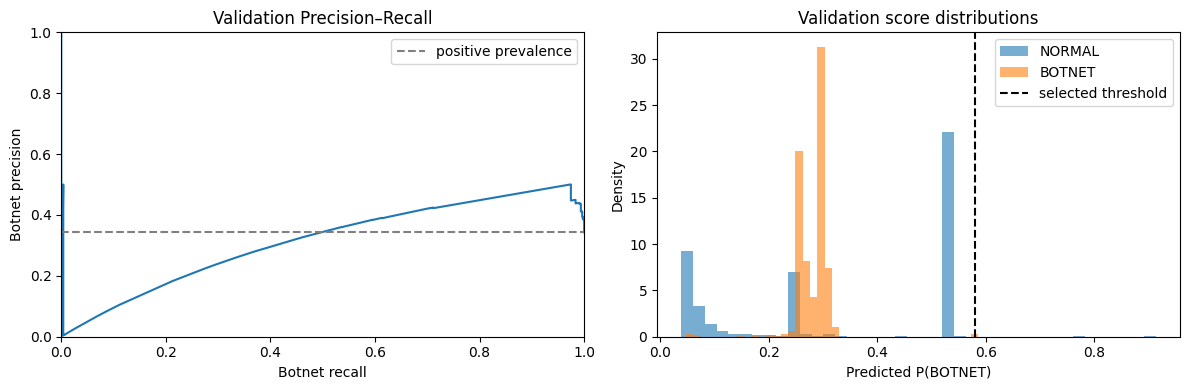

107

In [92]:
curve_precision,curve_recall,_=precision_recall_curve(yv,pv)
try:
    ap=float(average_precision_score(yv,pv));auc=float(roc_auc_score(yv,pv))
except ValueError:ap=auc=float('nan')
print('Validation AP:',ap,'ROC-AUC:',auc,'class prevalence:',float(yv.mean()))
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].plot(curve_recall,curve_precision)
axs[0].axhline(yv.mean(),color='gray',ls='--',label='positive prevalence')
axs[0].set(xlabel='Botnet recall',ylabel='Botnet precision',title='Validation Precision–Recall',xlim=(0,1),ylim=(0,1));axs[0].legend()
axs[1].hist(pv[yv==0],bins=40,alpha=.6,label='NORMAL',density=True)
axs[1].hist(pv[yv==1],bins=40,alpha=.6,label='BOTNET',density=True)
axs[1].axvline(selected,ls='--',color='black',label='selected threshold')
axs[1].set(xlabel='Predicted P(BOTNET)',ylabel='Density',title='Validation score distributions');axs[1].legend()
plt.tight_layout();plt.savefig(OUT/'validation_pr_scores.png',dpi=170);plt.show()
(OUT/'validation_ranking_metrics.json').write_text(json.dumps({'ap':ap,'roc_auc':auc,'botnet_prevalence':float(yv.mean())},indent=2))

## 7. Đánh giá test scenario 12 **một lần với ngưỡng đã khóa**


 validation scenario 11


,precision,recall,f1-score,support
NORMAL,0.657630,0.998009,0.792831,1507.000000
BOTNET,0.500000,0.003817,0.007576,786.000000
accuracy,0.657218,0.657218,0.657218,0.657218
macro avg,0.578815,0.500913,0.400203,2293.000000
weighted avg,0.603597,0.657218,0.523659,2293.000000


Confusion Matrix [NORMAL, BOTNET]:
 [[1504    3]
 [ 783    3]]

 test scenario 12


,precision,recall,f1-score,support
NORMAL,0.776970,0.978068,0.865998,6885.000000
BOTNET,0.307339,0.033500,0.060415,2000.000000
accuracy,0.765447,0.765447,0.765447,0.765447
macro avg,0.542155,0.505784,0.463206,8885.000000
weighted avg,0.671257,0.765447,0.684662,8885.000000


Confusion Matrix [NORMAL, BOTNET]:
 [[6734  151]
 [1933   67]]


,split,scenario,threshold,n,accuracy,botnet_precision,botnet_recall,botnet_f1,macro_f1,fpr,TN,FP,FN,TP
0,validation,11,0.58,2293,0.657218,0.500000,0.003817,0.007576,0.400203,0.001991,1504,3,783,3
1,test,12,0.58,8885,0.765447,0.307339,0.033500,0.060415,0.463206,0.021932,6734,151,1933,67


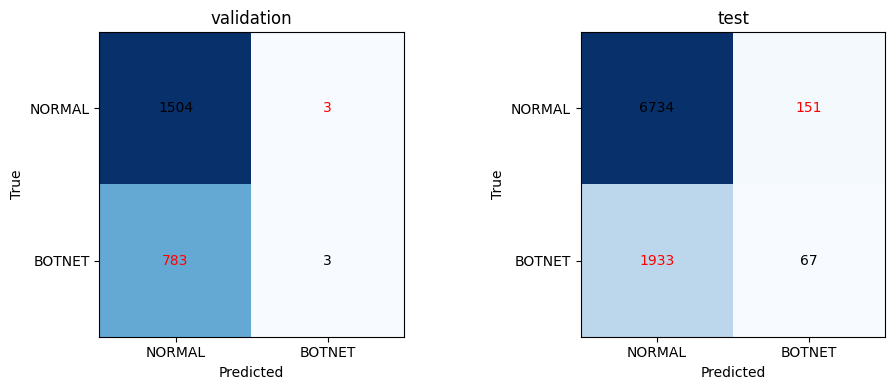

In [93]:
def report_split(split,threshold):
    y=Y[split];p=probs[split];pred=(p>=threshold).astype(int)
    d={'split':split,'scenario':SPLITS[split],'threshold':threshold,'n':len(y),**calc_metrics(y,pred)}
    rep=pd.DataFrame(classification_report(y,pred,labels=[0,1],target_names=['NORMAL','BOTNET'],
                        output_dict=True,zero_division=0)).T
    cm=confusion_matrix(y,pred,labels=[0,1])
    rep.to_csv(OUT/f'{split}_classification_report.csv')
    pd.DataFrame(cm,index=['True_NORMAL','True_BOTNET'],columns=['Pred_NORMAL','Pred_BOTNET']).to_csv(OUT/f'{split}_confusion_matrix.csv')
    pd.DataFrame({'true_label':y,'p_botnet':p,'pred_label':pred}).to_csv(OUT/f'{split}_predictions.csv',index=False)
    print('\n',split,'scenario',SPLITS[split]);display(rep)
    print('Confusion Matrix [NORMAL, BOTNET]:\n',cm)
    return d,cm
val_metrics,val_cm=report_split('validation',selected)
test_metrics,test_cm=report_split('test',selected)
summary=pd.DataFrame([val_metrics,test_metrics])
summary.to_csv(OUT/'selected_threshold_comparison.csv',index=False)
display(summary)
fig,axs=plt.subplots(1,2,figsize=(10,4))
for ax,(split,cm) in zip(axs,[('validation',val_cm),('test',test_cm)]):
    im=ax.imshow(cm,cmap='Blues')
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['NORMAL','BOTNET'],yticklabels=['NORMAL','BOTNET'],xlabel='Predicted',ylabel='True',title=split)
    for (i,j),v in np.ndenumerate(cm):ax.text(j,i,str(v),ha='center',va='center',color='red' if i!=j else 'black')
plt.tight_layout();plt.savefig(OUT/'validation_test_confusions.png',dpi=170);plt.show()

## 8. Kết luận giới hạn & manifest để chuyển sang 08–09

In [94]:
manifest={
 'notebook':'07_CTU_Cross_Scenario_Drift_Threshold_Audit',
 'actual_task':'flow-only scenario shift audit and validation-only threshold selection',
 'source_type':source_type,'scenarios':SPLITS,
 'features':FEATURES,'label_policy':'known NORMAL/BOTNET only; UNKNOWN excluded from supervised metrics',
 'graph_feasibility':readiness,'model_origin':model_origin,
 'threshold_selection':selection,
 'final_validation_metrics':val_metrics,'final_test_metrics':test_metrics,
 'warning':'Previous 06 test exposed; scenario 12 evaluation is exploratory, not a new blind test',
 'next_steps':{'08':'Cross-scenario robustness study on flow-only features; do not call temporal without timestamps',
               '09':'Final evaluation across tasks with separate CIC/CTU metrics, no pooled cross-dataset scores'}}
(OUT/'experiment_manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False))
print('Saved artifacts:',len(list(OUT.iterdir())))
for p in sorted(OUT.iterdir()):print(' -',p.name)
if test_metrics['botnet_recall']<0.5:
    print('WARNING: Botnet recall below 50%; DO NOT declare model deployment-ready.')
print('No host topology, beaconing, or temporal model was created without the necessary raw fields.')

Saved artifacts: 18
 - ctu_rf_frozen.joblib
 - experiment_manifest.json
 - feature_distribution_drift.csv
 - scenario_label_audit.csv
 - schema_readiness.json
 - selected_threshold_comparison.csv
 - test_classification_report.csv
 - test_confusion_matrix.csv
 - test_predictions.csv
 - validation_classification_report.csv
 - validation_confusion_matrix.csv
 - validation_pr_scores.png
 - validation_predictions.csv
 - validation_ranking_metrics.json
 - validation_test_confusions.png
 - validation_threshold_grid.csv
 - validation_threshold_selection.json
 - validation_threshold_tradeoff.png
No host topology, beaconing, or temporal model was created without the necessary raw fields.
